In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.models import Sequential

# Modelo LSTM Unidirecional - Baselines Abordagem B

Para validar a acurácia de um modelo de redes neurais recorrentes e justificar a sua utilização bem como a evolução de sua estrutura, os seguintes testes serão submetidos:

### 1. Auto-previsão do ERA5
##### ($\text{ws100_era5} \rightarrow \text{ws100_era5}$) — Abordagem B

O primeiro experimento da **Abordagem B** consiste no teste de auto-previsão autorregressiva de controle (*sanity check*), no qual o modelo é treinado para prever as tendências da própria série temporal da reanálise atmosférica ERA5 interpolada para a resolução de 10 minutos (`ws100_era5`).

O objetivo é **validar o funcionamento do pipeline em alta resolução temporal** e analisar a resposta da LSTM perante um sinal cujos pontos sub-horários foram gerados por interpolação linear.

A implementação dessa *baseline* segue as seguintes diretrizes metodológicas:

---

### Divisão Cronológica do Dataset
O dataset na resolução de 10 minutos (**Abordagem B**) contém exatos **4.195 pontos coincidentes**. Respeitando a ordem temporal cronológica para evitar vazamento de dados (*data leakage*), a base foi dividida em:
* **Treinamento (70%):** 2.936 registros (resultando em 2.792 sequências de entrada após o desconto da janela deslizante de 144 passos);
* **Validação (15%):** 629 registros (aproximadamente 485 sequências para ajuste de hiperparâmetros);
* **Teste (15%):** 630 registros (aproximadamente 486 sequências para inferência final e avaliação de métricas).

---

### Parametrização da Arquitetura Neural
* **Histórico de Entrada (*Lookback*):** 144 *timestamps* (representando 24 horas de histórico passado na resolução de 10 minutos, pois $144 \times 10\text{ min} = 1.440\text{ min} = 24\text{h}$);
* **Tamanho do Lote (*Batch Size*):** 64 amostras, valor otimizado para o volume do conjunto de treinamento (~2.792 sequências, gerando cerca de 44 atualizações de pesos por época);
* **Camada Recorrente:** Camada LSTM com 64 unidades ocultas e função de ativação $\tanh$ para captura de dependências temporais;
* **Regularização:** Camada *Dropout* com taxa de 0,2 (20%) para prevenir sobreajuste (*overfitting*);
* **Processamento Densa Intermediário:** Camada *Dense* com 32 neurônios e função de ativação $\text{ReLU}$;
* **Camada de Saída:**
  * Camada `Dense(HORIZON = 6)` para a previsão de passo único em resolução decaminutal ($+60\text{ min}$);
  * Camada `Dense(HORIZON = 36)` para a projeção direta do horizonte multi-passo ($+10\text{ min}$ a $+360\text{ min}$, cobrindo 6 horas à frente).

---

### Otimização e Estratégia de Controle (*Callbacks*)
* **Otimizador e Perda:** Algoritmo *Adam* minimizando a função de perda do Erro Quadrático Médio (MSE);
* **EarlyStopping:** Interrupção automática caso a perda de validação (`val_loss`) não apresente melhoria por 7 épocas consecutivas (`patience=7`), restaurando os pesos do melhor estado (`restore_best_weights=True`);
* **ReduceLROnPlateau:** Redução da taxa de aprendizado em 50% (`factor=0.5`) caso a `val_loss` estagne por 3 épocas (`patience=3`), com limite mínimo de $1\times10^{-5}$.






Formato de X_train (Amostras, Histórico, Atributos): (2779, 144, 1)
Formato de y_train (Amostras, Horizonte Futuro): (2779, 6)

Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.5733 - mae: 0.5772 - val_loss: 0.3141 - val_mae: 0.4181 - learning_rate: 0.0010
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.2034 - mae: 0.3518 - val_loss: 0.1556 - val_mae: 0.2973 - learning_rate: 0.0010
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.1409 - mae: 0.2869 - val_loss: 0.1129 - val_mae: 0.2476 - learning_rate: 0.0010
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.1157 - mae: 0.2604 - val_loss: 0.1082 - val_mae: 0.2454 - learning_rate: 0.0010
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.1038 - mae: 0.2451 - val_loss: 0.1005 - val_mae: 0.2352 - learning_rate: 0.0010
Epoch 6/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.0932 - mae: 0.2306 - val_loss: 0.0860 - val_mae: 0.2105 - learning_rate: 0.0010
Epoch 7/50
44/44 ━━━━━━━━━

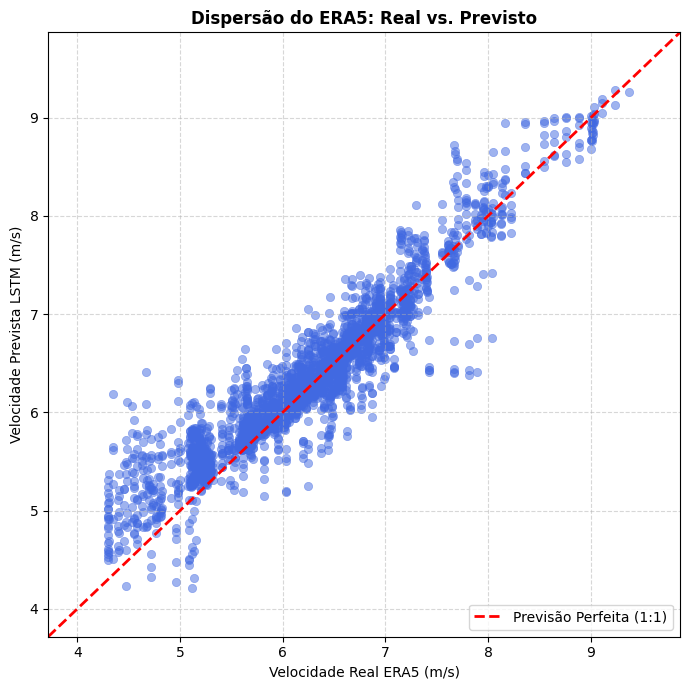

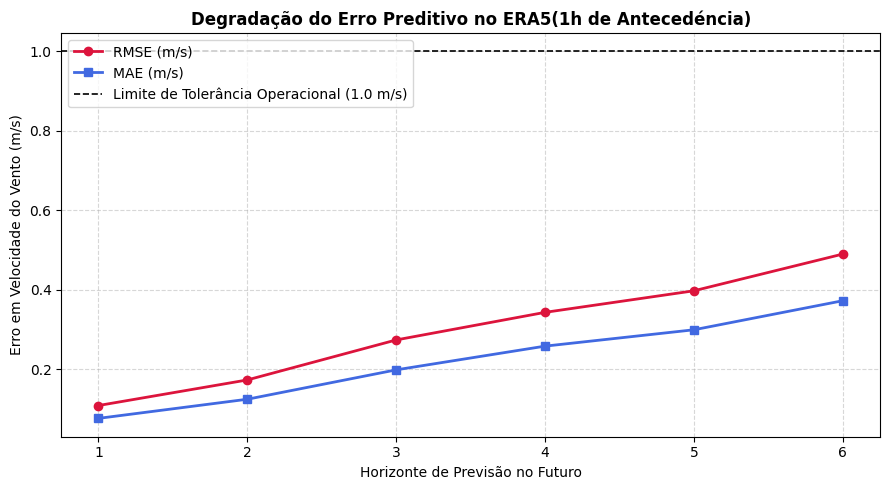

In [6]:
# ==========================================
# 1. CARREGAMENTO E DIVISÃO TEMPORAL
# ==========================================
df = pd.read_parquet("data/approach_b.parquet")

features = ["ws100_era5"]
target = "ws100_era5"

n = len(df)
train_df = df.iloc[: int(n * 0.7)]
val_df = df.iloc[int(n * 0.7) : int(n * 0.85)]
test_df = df.iloc[int(n * 0.85) :]

# ==========================================
# 2. NORMALIZAÇÃO SEPARADA (X e Y)
# ==========================================
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_raw = scaler_x.fit_transform(train_df[features])
y_train_raw = scaler_y.fit_transform(train_df[[target]])

X_val_raw = scaler_x.transform(val_df[features])
y_val_raw = scaler_y.transform(val_df[[target]])

X_test_raw = scaler_x.transform(test_df[features])
y_test_raw = scaler_y.transform(test_df[[target]])

# ==========================================
# 3. JANELA DESLIZANTE (SLIDING WINDOW)
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=6):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (6) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 6  # 1 hora de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 4. MODELO LSTM MULTI-STEP (Dense de Saída = 6)
# ==========================================
model = Sequential(
    [
        Input(
            shape=(X_train.shape[1], X_train.shape[2])
        ),
        LSTM(64, activation="tanh"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(HORIZON),
    ]
)

model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# Callbacks de controle
early_stop = EarlyStopping(
    monitor="val_loss", patience=7, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)

# ==========================================
# 5. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 6. AVALIAÇÃO PASSO A PASSO (1H ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 1h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 7. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 8. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h de Antecedéncia)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

#### Ampliação do Horizonte para 6 passos:

Formato de X_train (Amostras, Histórico, Atributos): (2749, 144, 1)
Formato de y_train (Amostras, Horizonte Futuro): (2749, 36)

Epoch 1/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 7s 101ms/step - loss: 0.8328 - mae: 0.7148 - val_loss: 1.1034 - val_mae: 0.8549 - learning_rate: 0.0010
Epoch 2/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.5966 - mae: 0.6040 - val_loss: 0.7160 - val_mae: 0.6578 - learning_rate: 0.0010
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.5209 - mae: 0.5575 - val_loss: 0.6304 - val_mae: 0.6012 - learning_rate: 0.0010
Epoch 4/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.4645 - mae: 0.5288 - val_loss: 0.5368 - val_mae: 0.5424 - learning_rate: 0.0010
Epoch 5/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.3917 - mae: 0.4844 - val_loss: 0.8368 - val_mae: 0.7129 - learning_rate: 0.0010
Epoch 6/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.3471 - mae: 0.4588 - val_loss: 0.6291 - val_mae: 0.5756 - learning_rate: 0.0010
Epoch 7/50
43/43 ━━━━━━━

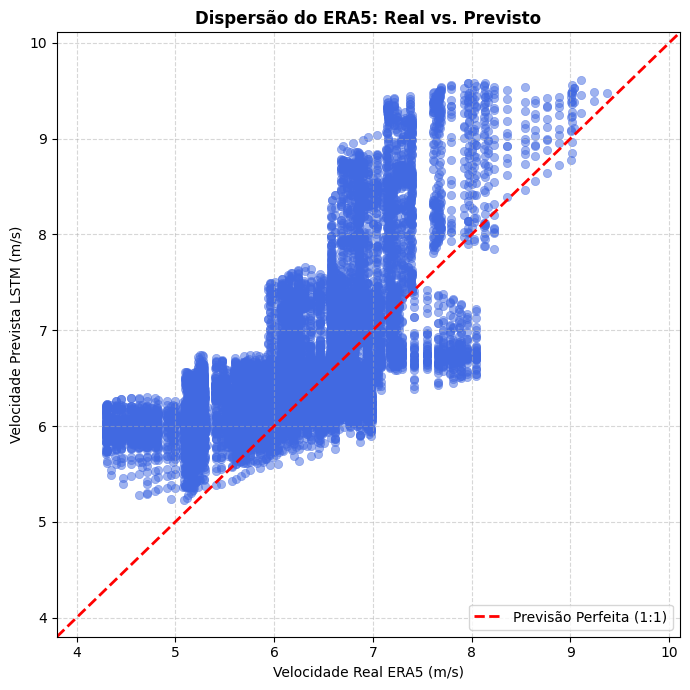

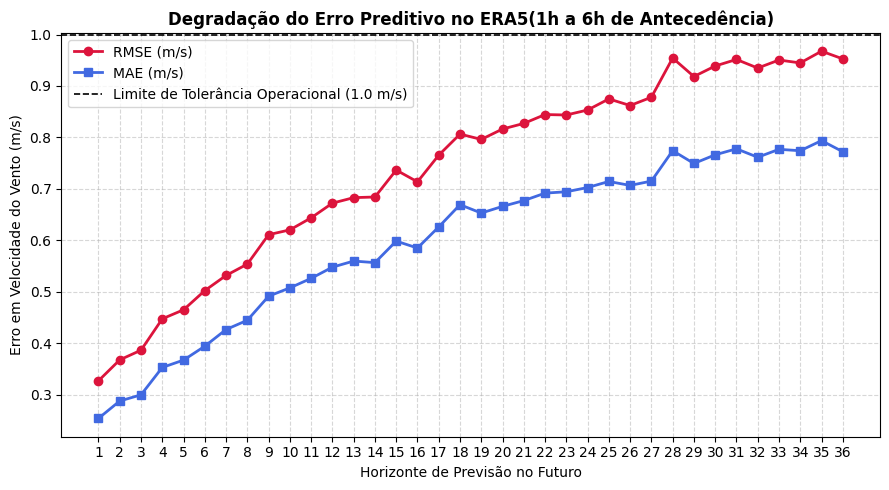

In [7]:
# ==========================================
# 9. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP (1 passo -> 6 passos)
# A ideia é entender se o modelo é capaz de se auto-prever em um horizonte de 6 passos
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=36):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (36) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 36  # 6 horas de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 10. MODELO LSTM MULTI-STEP (Dense de Saída = 6)
# ==========================================
model = Sequential(
    [
        Input(
            shape=(X_train.shape[1], X_train.shape[2])
        ),
        LSTM(64, activation="tanh"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(HORIZON),
    ]
)

model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# Callbacks de controle
early_stop = EarlyStopping(
    monitor="val_loss", patience=7, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)

# ==========================================
# 11. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 12. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 7. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 13. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 2. Previsão do Vento LiDAR Filtrado
#### ($\text{ws100_lidar_clean} \rightarrow \text{ws100_lidar}$) — Abordagem B

O segundo experimento consiste no teste autorregressivo em alta resolução temporal com sinal suavizado, no qual a LSTM é alimentada pela série temporal alinhada LiDAR/ERA5 filtrada por Wavelet (`ws100_lidar_clean`) para prever a velocidade real e instantânea do vento (`ws100_lidar`) na escala nativa de 10 minutos.

O objetivo é **avaliar a inércia de curtíssimo prazo** e medir até que ponto a filtragem Wavelet (`sym18`, nível 2) sustenta a acurácia do modelo passo a passo ao longo dos primeiros 60 minutos.

A implementação dessa *baseline* segue as seguintes diretrizes metodológicas:

---

### Divisão Cronológica do Dataset
Dataset contendo **4.195 registros** de 10 minutos. Respeitando a ordem cronológica estrita:
* **Treinamento (70%):** 2.936 registros (2.792 sequências efetivas);
* **Validação (15%):** 629 registros (485 sequências);
* **Teste (15%):** 630 registros (486 sequências).

---

### Parametrização da Arquitetura Neural
* **Histórico de Entrada (*Lookback*):** 144 *timestamps* (24 horas de histórico em passos de 10 minutos);
* **Tamanho do Lote (*Batch Size*):** 64 amostras;
* **Camada Recorrente:** Camada LSTM com 64 unidades ocultas e ativação $\tanh$;
* **Regularização:** *Dropout* de 0,2 (20%);
* **Processamento Densa Intermediário:** Camada *Dense* com 32 neurônios e ativação $\text{ReLU}$;
* **Camada de Saída:**
  * Camada `Dense(HORIZON = 6)` para passo único ($+60\text{ min}$);
  * Camada `Dense(HORIZON = 36)` para projeção direta dos 6 passos ($+10\text{ min}$ a $+360\text{ min}$).

---

### Otimização e Estratégia de Controle (*Callbacks*)
* **Otimizador e Perda:** *Adam* minimizando o Erro Quadrático Médio (MSE);
* **EarlyStopping:** `patience=7`, `restore_best_weights=True`;
* **ReduceLROnPlateau:** `patience=3`, `factor=0.5`, `min_lr=1e-5`.

Formato de X_train (Amostras, Histórico, Atributos): (2779, 144, 1)
Formato de y_train (Amostras, Horizonte Futuro): (2779, 6)

Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - loss: 0.7344 - mae: 0.6591 - val_loss: 0.5876 - val_mae: 0.5674 - learning_rate: 0.0010
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 0.5319 - mae: 0.5440 - val_loss: 0.5074 - val_mae: 0.5193 - learning_rate: 0.0010
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.4575 - mae: 0.4990 - val_loss: 0.4978 - val_mae: 0.5151 - learning_rate: 0.0010
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - loss: 0.4322 - mae: 0.4844 - val_loss: 0.4840 - val_mae: 0.5039 - learning_rate: 0.0010
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.4198 - mae: 0.4758 - val_loss: 0.4560 - val_mae: 0.4875 - learning_rate: 0.0010
Epoch 6/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.4060 - mae: 0.4684 - val_loss: 0.4494 - val_mae: 0.4867 - learning_rate: 0.0010
Epoch 7/50
44/44 ━━━━━━━━━

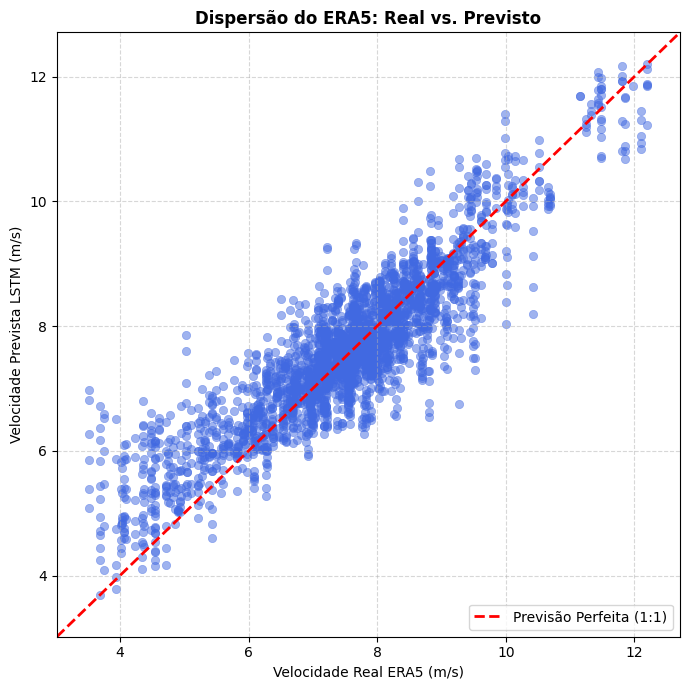

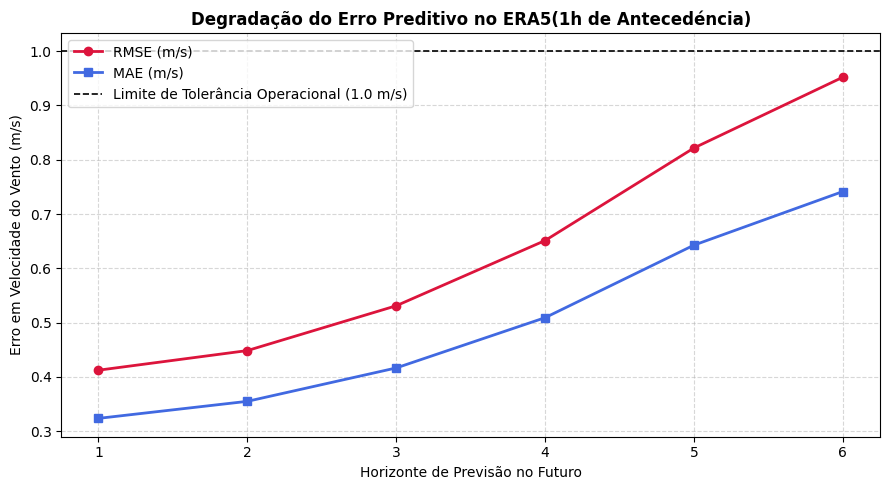

In [8]:
# ==========================================
# 1. CARREGAMENTO E DIVISÃO TEMPORAL
# ==========================================
df = pd.read_parquet("data/approach_b.parquet")

features = ["ws100_lidar_clean"]
target = "ws100_lidar"

n = len(df)
train_df = df.iloc[: int(n * 0.7)]
val_df = df.iloc[int(n * 0.7) : int(n * 0.85)]
test_df = df.iloc[int(n * 0.85) :]

# ==========================================
# 2. NORMALIZAÇÃO SEPARADA (X e Y)
# ==========================================
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_raw = scaler_x.fit_transform(train_df[features])
y_train_raw = scaler_y.fit_transform(train_df[[target]])

X_val_raw = scaler_x.transform(val_df[features])
y_val_raw = scaler_y.transform(val_df[[target]])

X_test_raw = scaler_x.transform(test_df[features])
y_test_raw = scaler_y.transform(test_df[[target]])

# ==========================================
# 3. JANELA DESLIZANTE (SLIDING WINDOW)
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=6):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (6) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 6  # 1 hora de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 4. MODELO LSTM MULTI-STEP
# ==========================================
model = Sequential(
    [
        Input(
            shape=(X_train.shape[1], X_train.shape[2])
        ),
        LSTM(64, activation="tanh"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(HORIZON),
    ]
)

model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# Callbacks de controle
early_stop = EarlyStopping(
    monitor="val_loss", patience=7, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)

# ==========================================
# 5. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 6. AVALIAÇÃO PASSO A PASSO (1H ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 1h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 7. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 8. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h de Antecedéncia)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Ampliando para 6 horas

Formato de X_train (Amostras, Histórico, Atributos): (2749, 144, 1)
Formato de y_train (Amostras, Horizonte Futuro): (2749, 36)

Epoch 1/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - loss: 0.9333 - mae: 0.7506 - val_loss: 0.8155 - val_mae: 0.7067 - learning_rate: 0.0010
Epoch 2/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - loss: 0.7889 - mae: 0.6864 - val_loss: 0.7125 - val_mae: 0.6456 - learning_rate: 0.0010
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.7487 - mae: 0.6654 - val_loss: 0.7020 - val_mae: 0.6424 - learning_rate: 0.0010
Epoch 4/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.7325 - mae: 0.6557 - val_loss: 0.7111 - val_mae: 0.6566 - learning_rate: 0.0010
Epoch 5/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.7233 - mae: 0.6520 - val_loss: 0.6685 - val_mae: 0.6188 - learning_rate: 0.0010
Epoch 6/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.7127 - mae: 0.6447 - val_loss: 0.6687 - val_mae: 0.6294 - learning_rate: 0.0010
Epoch 7/50
43/43 ━━━━━━━━

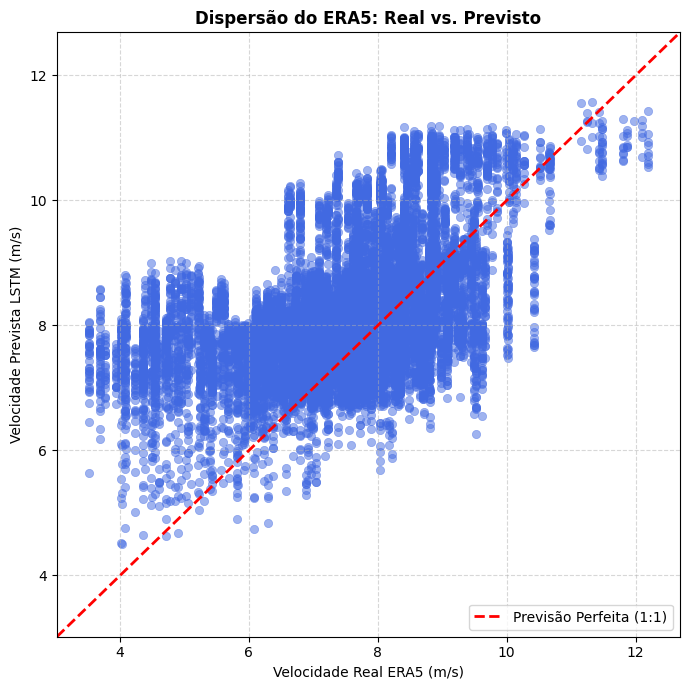

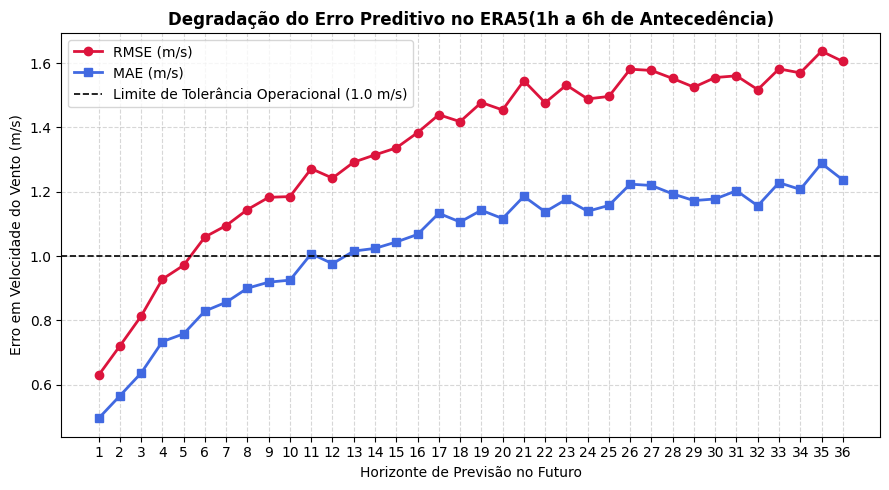

In [9]:
# ==========================================
# 9. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP (1 passo -> 6 passos)
# A ideia é entender se o modelo é capaz de se auto-prever em um horizonte de 6 passos
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=36):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (36) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 36  # 6 horas de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 10. MODELO LSTM MULTI-STEP (Dense de Saída = 6)
# ==========================================
model = Sequential(
    [
        Input(
            shape=(X_train.shape[1], X_train.shape[2])
        ),
        LSTM(64, activation="tanh"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(HORIZON),
    ]
)

model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# Callbacks de controle
early_stop = EarlyStopping(
    monitor="val_loss", patience=7, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)

# ==========================================
# 11. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 12. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 13. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 14. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 3. Previsão com Vetor Misto
#### ($\text{ws100_lidar_clean} + \text{ws100_era5} \rightarrow \text{ws100_lidar}$) — Abordagem B

O terceiro experimento da **Abordagem B** aborda a **fusão multivariada de dados em alta resolução**, combinando a série do LiDAR/ERA5 filtrada por Wavelet (`ws100_lidar_clean`) e a reanálise do ERA5 (`ws100_era5`) como insumos simultâneos para estimar a velocidade real (`ws100_lidar`).

O objetivo é **verificar se a amostragem de ~2.792 sequências na escala decaminutal é suficiente para estabilizar o aprendizado de atributos heterogêneos** sob uma arquitetura de camada densa direta.

A implementação dessa *baseline* segue as seguintes diretrizes metodológicas:

---

### Divisão Cronológica do Dataset
Dataset contendo **4.195 registros** de 10 minutos. Respeitando a ordem cronológica estrita:
* **Treinamento (70%):** 2.936 registros (2.792 sequências multivariadas);
* **Validação (15%):** 629 registros (485 sequências);
* **Teste (15%):** 630 registros (486 sequências).

---

### Parametrização da Arquitetura Neural
* **Histórico de Entrada (*Lookback*):** 144 *timestamps* (24 horas de histórico multivariado com 2 atributos em cada passo);
* **Tamanho do Lote (*Batch Size*):** 64 amostras;
* **Camada Recorrente:** Camada LSTM com 64 unidades ocultas e ativação $\tanh$;
* **Regularização:** *Dropout* de 0,2 (20%);
* **Processamento Densa Intermediário:** Camada *Dense* com 32 neurônios e ativação $\text{ReLU}$;
* **Camada de Saída:**
  * Camada `Dense(HORIZON = 6)` para passo único ($+60\text{ min}$);
  * Camada `Dense(HORIZON = 36)` para a projeção multi-passo ($+10\text{ min}$ a $+360\text{ min}$).

---

### Otimização e Estratégia de Controle (*Callbacks*)
* **Otimizador e Perda:** *Adam* minimizando o Erro Quadrático Médio (MSE);
* **EarlyStopping:** `patience=7`, `restore_best_weights=True`;
* **ReduceLROnPlateau:** `patience=3`, `factor=0.5`, `min_lr=1e-5`.

Formato de X_train (Amostras, Histórico, Atributos): (2779, 144, 2)
Formato de y_train (Amostras, Horizonte Futuro): (2779, 6)

Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.6794 - mae: 0.6226 - val_loss: 0.5430 - val_mae: 0.5437 - learning_rate: 0.0010
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.4876 - mae: 0.5157 - val_loss: 0.5137 - val_mae: 0.5273 - learning_rate: 0.0010
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - loss: 0.4329 - mae: 0.4820 - val_loss: 0.4989 - val_mae: 0.5200 - learning_rate: 0.0010
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.4144 - mae: 0.4708 - val_loss: 0.4750 - val_mae: 0.5055 - learning_rate: 0.0010
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 0.3988 - mae: 0.4616 - val_loss: 0.4595 - val_mae: 0.4974 - learning_rate: 0.0010
Epoch 6/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.3918 - mae: 0.4571 - val_loss: 0.4520 - val_mae: 0.4929 - learning_rate: 0.0010
Epoch 7/50
44/44 ━━━━━━━━━

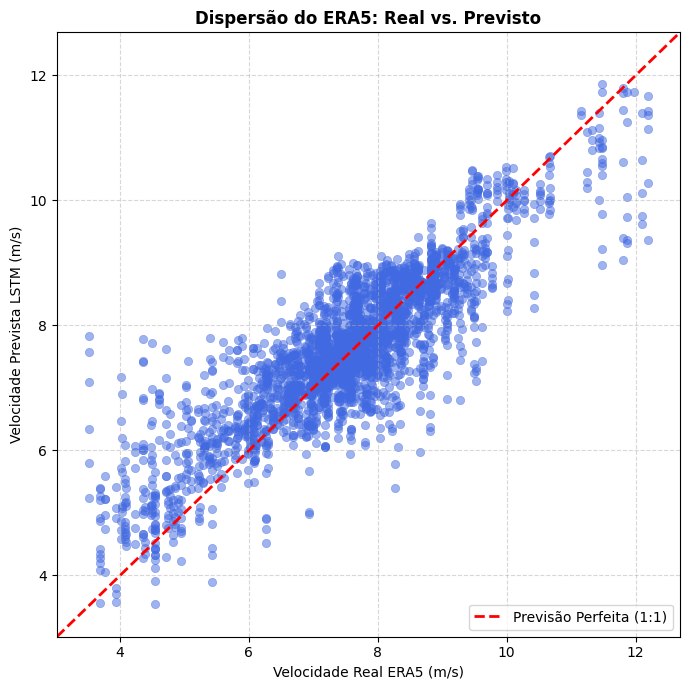

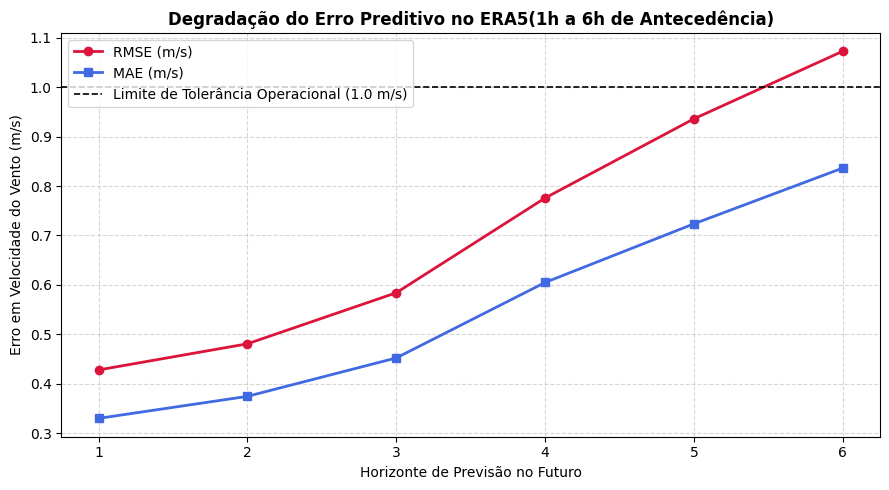

In [12]:
# ==========================================
# 1. CARREGAMENTO E PREPARAÇÃO DOS DADOS (Abordagem B)
# ==========================================
df = pd.read_parquet("data/approach_b.parquet")

# Features de entrada (X): ERA5 e LiDAR filtrado por Wavelet
features = ["ws100_era5", "ws100_lidar_clean"]
# Alvo (Y): Verdade de campo do LiDAR
target = "ws100_lidar"

# ==========================================
# 2. DIVISÃO TEMPORAL CRONOLÓGICA (70% / 15% / 15%)
# ==========================================
n = len(df)
train_df = df.iloc[: int(n * 0.7)]
val_df = df.iloc[int(n * 0.7) : int(n * 0.85)]
test_df = df.iloc[int(n * 0.85) :]

# ==========================================
# 3. NORMALIZAÇÃO SEPARADA (X e Y)
# ==========================================
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_raw = scaler_x.fit_transform(train_df[features])
y_train_raw = scaler_y.fit_transform(train_df[[target]])

X_val_raw = scaler_x.transform(val_df[features])
y_val_raw = scaler_y.transform(val_df[[target]])

X_test_raw = scaler_x.transform(test_df[features])
y_test_raw = scaler_y.transform(test_df[[target]])

# ==========================================
# 4. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=6):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (36) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 6  # 6 horas de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 5. MODELO LSTM MULTI-STEP
# ==========================================
model = Sequential(
    [
        Input(
            shape=(X_train.shape[1], X_train.shape[2])
        ),
        LSTM(64, activation="tanh"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(HORIZON),
    ]
)

model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# Callbacks de controle
early_stop = EarlyStopping(
    monitor="val_loss", patience=7, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)

# ==========================================
# 6. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 7. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 8. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 9. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Ampliando para 6 horas

Formato de X_train (Amostras, Histórico, Atributos): (2749, 144, 2)
Formato de y_train (Amostras, Horizonte Futuro): (2749, 36)

Epoch 1/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.8914 - mae: 0.7289 - val_loss: 0.7316 - val_mae: 0.6518 - learning_rate: 0.0010
Epoch 2/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.7385 - mae: 0.6596 - val_loss: 0.7830 - val_mae: 0.6696 - learning_rate: 0.0010
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.6842 - mae: 0.6329 - val_loss: 0.7605 - val_mae: 0.6580 - learning_rate: 0.0010
Epoch 4/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - loss: 0.6648 - mae: 0.6204 - val_loss: 0.8238 - val_mae: 0.6907 - learning_rate: 0.0010
Epoch 5/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.6485 - mae: 0.6133 - val_loss: 0.7124 - val_mae: 0.6343 - learning_rate: 5.0000e-04
Epoch 6/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 0.6347 - mae: 0.6062 - val_loss: 0.7072 - val_mae: 0.6315 - learning_rate: 5.0000e-04
Epoch 7/50
43/43 

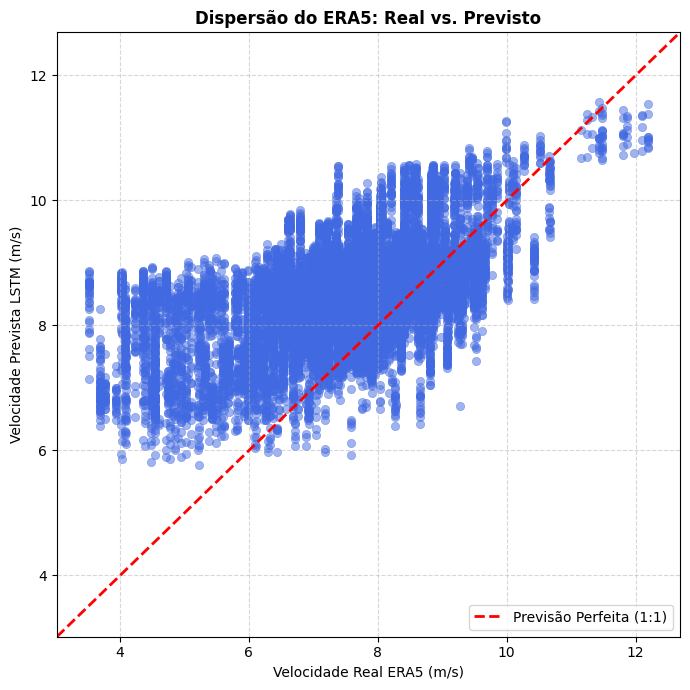

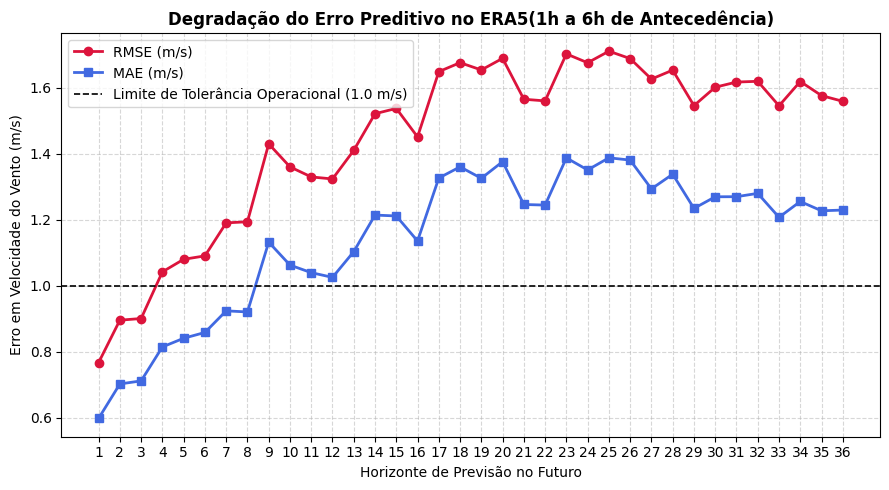

In [13]:
# ==========================================
# 10. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP (1 passo -> 6 passos)
# A ideia é entender se o modelo é capaz de se auto-prever em um horizonte de 6 passos
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=36):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (36) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 36  # 6 horas de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 11. MODELO LSTM MULTI-STEP
# ==========================================
model = Sequential(
    [
        Input(
            shape=(X_train.shape[1], X_train.shape[2])
        ),
        LSTM(64, activation="tanh"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(HORIZON),
    ]
)

model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# Callbacks de controle
early_stop = EarlyStopping(
    monitor="val_loss", patience=7, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)

# ==========================================
# 12. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 13. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 14. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 15. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Conclusões
